# SPRINT 14 - PROYECTO


## Paso 1. Análisis exploratorio de datos (EDA)

### Abrir el archivo de datos y cargar las librerias

In [47]:
# Se importan las todas las librerías que se ocuparán para el análisis
import pandas as pd
import datetime as dt
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from scipy import stats as st
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score, recall_score

# Se cargan los archivos
df = pd.read_csv('gym_churn_us.csv')

### Previsualización de la información que contiene el DataFrame

In [48]:
# Se muestra información y detalles de los datos que contiene el DataFrame
df.info()
print ()
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float

### Limpieza/correccion de datos del DataFrame

In [49]:
# Aseguramos que las columnas estén en minúsculas y tener un mejor manejo de las mismas
df.columns = df.columns.str.lower()
print(df.columns)

Index(['gender', 'near_location', 'partner', 'promo_friends', 'phone',
       'contract_period', 'group_visits', 'age',
       'avg_additional_charges_total', 'month_to_end_contract', 'lifetime',
       'avg_class_frequency_total', 'avg_class_frequency_current_month',
       'churn'],
      dtype='object')


### Se comprueba los tipos de datos y valores ausentes. Se corrigen los datos si es necesario.

In [50]:
# Verificamos si tenemos datos nulos
print ("Datos nulos:\n", df.isna().sum())
print ()
# Verificamos si tenemos datos duplicados
duplicates = df.duplicated().sum()
print ("Datos duplicados: ", duplicates)

Datos nulos:
 gender                               0
near_location                        0
partner                              0
promo_friends                        0
phone                                0
contract_period                      0
group_visits                         0
age                                  0
avg_additional_charges_total         0
month_to_end_contract                0
lifetime                             0
avg_class_frequency_total            0
avg_class_frequency_current_month    0
churn                                0
dtype: int64

Datos duplicados:  0


### Nueva visualizacion de columnas, datos y tipos de datos

In [51]:
# Volvemos a analizar los datos de nuestro DataFrame con las modificaciones hechas previamente
print (df.sample(5))
print()
print(df.columns)
print()
df.describe()

      gender  near_location  partner  promo_friends  phone  contract_period  \
976        0              1        0              0      1               12   
814        0              1        1              1      1               12   
3224       0              1        1              1      1                6   
2931       0              0        0              0      1                6   
2573       0              1        0              0      1                1   

      group_visits  age  avg_additional_charges_total  month_to_end_contract  \
976              1   32                    290.047394                   11.0   
814              0   31                    179.134940                   11.0   
3224             0   36                    165.197097                    6.0   
2931             0   26                    112.348304                    6.0   
2573             0   28                     71.123606                    1.0   

      lifetime  avg_class_frequency_total  a

,gender,near_location,partner,promo_friends,phone,contract_period,group_visits,age,avg_additional_charges_total,month_to_end_contract,lifetime,avg_class_frequency_total,avg_class_frequency_current_month,churn
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,0.510250,0.845250,0.486750,0.308500,0.903500,4.681250,0.412250,29.184250,146.943728,4.322750,3.724750,1.879020,1.767052,0.265250
std,0.499957,0.361711,0.499887,0.461932,0.295313,4.549706,0.492301,3.258367,96.355602,4.191297,3.749267,0.972245,1.052906,0.441521
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,18.000000,0.148205,1.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,27.000000,68.868830,1.000000,1.000000,1.180875,0.963003,0.000000
50%,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,29.000000,136.220159,1.000000,3.000000,1.832768,1.719574,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,6.000000,1.000000,31.000000,210.949625,6.000000,5.000000,2.536078,2.510336,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,12.000000,1.000000,41.000000,552.590740,12.000000,31.000000,6.023668,6.146783,1.000000


Al analizar el conteo de cada característica, todas tienen 4,000 registros, esto confirma que no hay valores ausentes en el dataset y no se encontraron valores nulos ni duplicados, así que el dataset está limpio y no se necesita 'limpiar' o eliminar filas.

Al analizar la tabla se puede decir que esta dividida en dos clases; una con lectura de variables binarias y otra con lectura de variables cuantitativas continuas



### Estudio de la distribución para los clientes que se quedaron vs. los que cancelaron

In [52]:
churn = df.groupby('churn').mean()
print(churn)


         gender  near_location   partner  promo_friends     phone  \
churn                                                               
0      0.510037       0.873086  0.534195       0.353522  0.903709   
1      0.510839       0.768143  0.355325       0.183789  0.902922   

       contract_period  group_visits        age  avg_additional_charges_total  \
churn                                                                           
0             5.747193      0.464103  29.976523                    158.445715   
1             1.728558      0.268615  26.989632                    115.082899   

       month_to_end_contract  lifetime  avg_class_frequency_total  \
churn                                                               
0                   5.283089  4.711807                   2.024876   
1                   1.662582  0.990575                   1.474995   

       avg_class_frequency_current_month  
churn                                     
0                               2.0

Al analizar los promedios de las caracteristicas, se puede obsrvar que 'phone' y 'gender' no influyen en la decisión de abandonar oquedarse en el gimnasio pues la diferencias es minima o csi inexistente.

Personas que se quedaron (0): Al calcular el promedio de asistencia, se nota que el 53.4% trabaja en una empresa asociada (vs. 35.5% en el grupo que cancela) y el 35.4% llegó por recomendación de un amigo (vs. 18.4% en el grupo que cancela), por lo que tener vínculos laborales o sociales refuerza la permanencia, eso se confirma con la columna de 'group_visits' donde el 46.4% de los usuarios asiste a clases grupales, comparado con solo el 26.9% del grupo que cancela.

Personas que abandonaron (1): Al calcular su promedio, se nota que los clientes que cancelan tienen una antigüedad de solo 0.99 meses (menos de un mes), en comparación con los 4.71 meses del grupo que se queda, la gran mayoría abandona durante su primer mes, el contrato medio es de solo 1.73 meses (predominan los pases mensuales de 1 mes)

### Graficos para las personas que se fueron y para las que se quedaron.

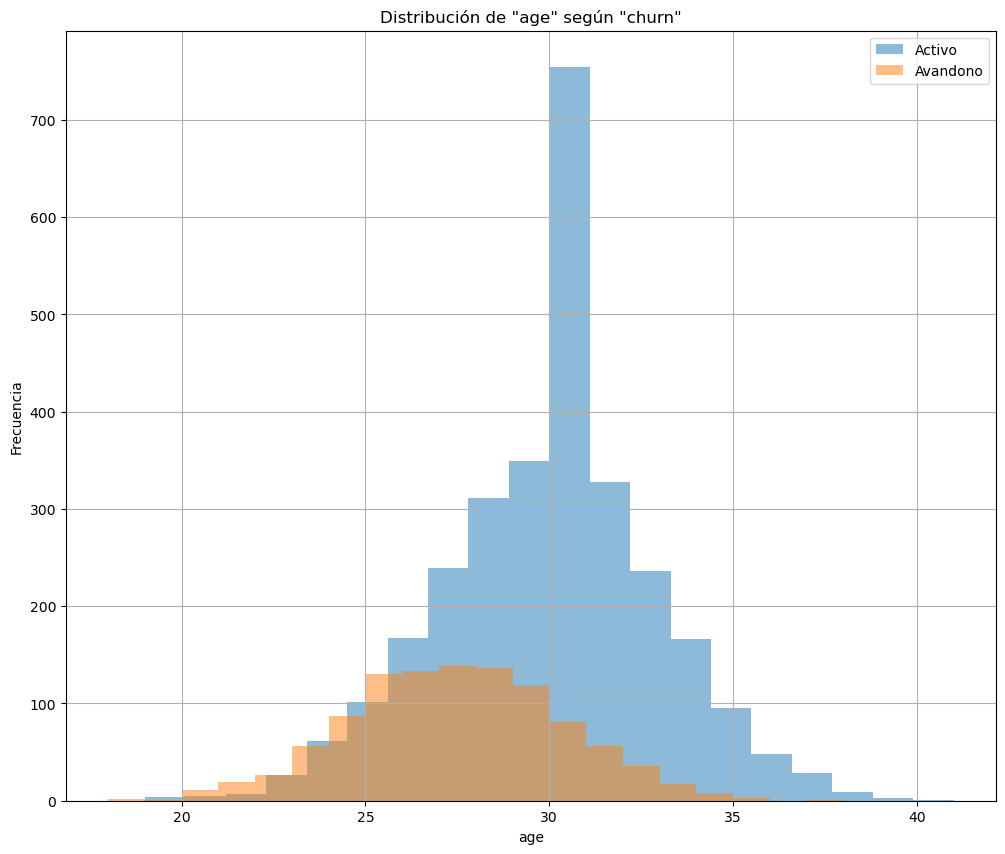

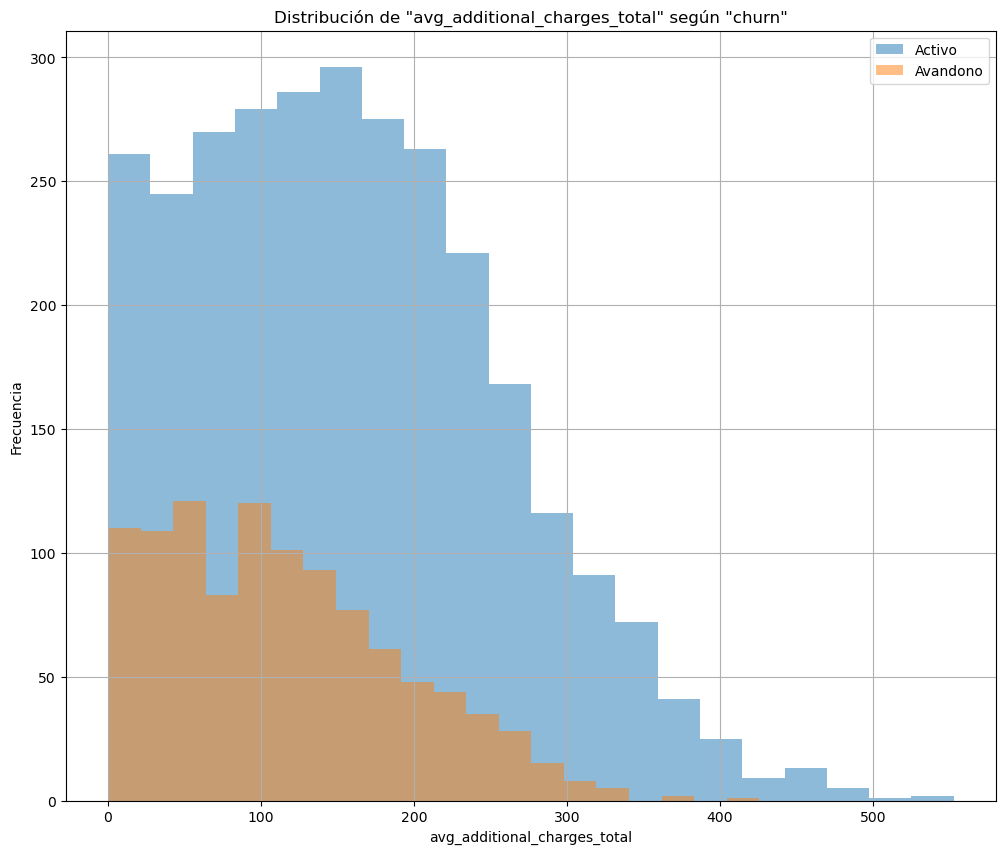

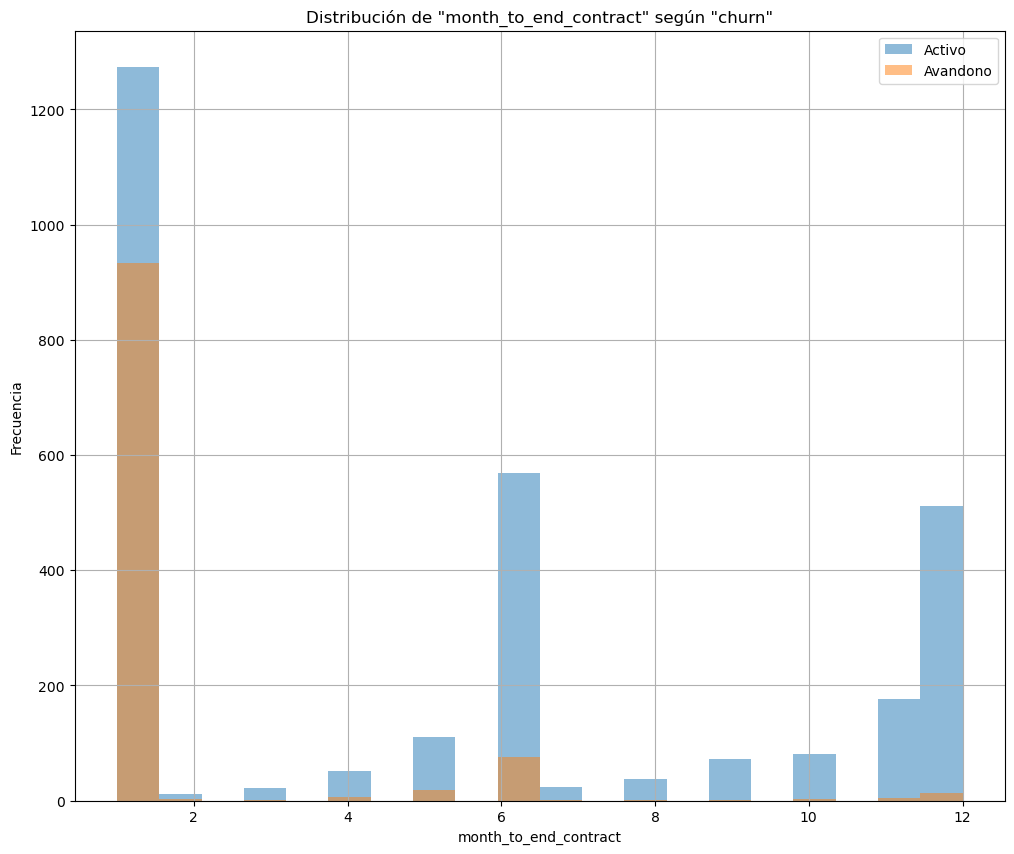

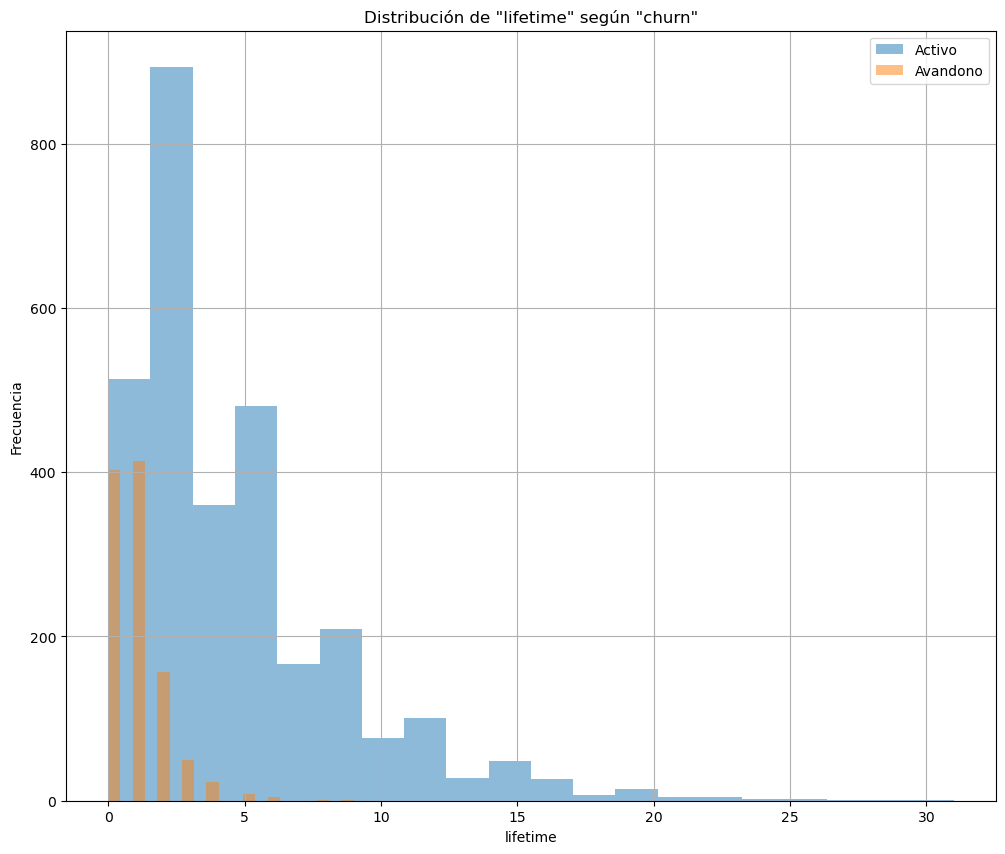

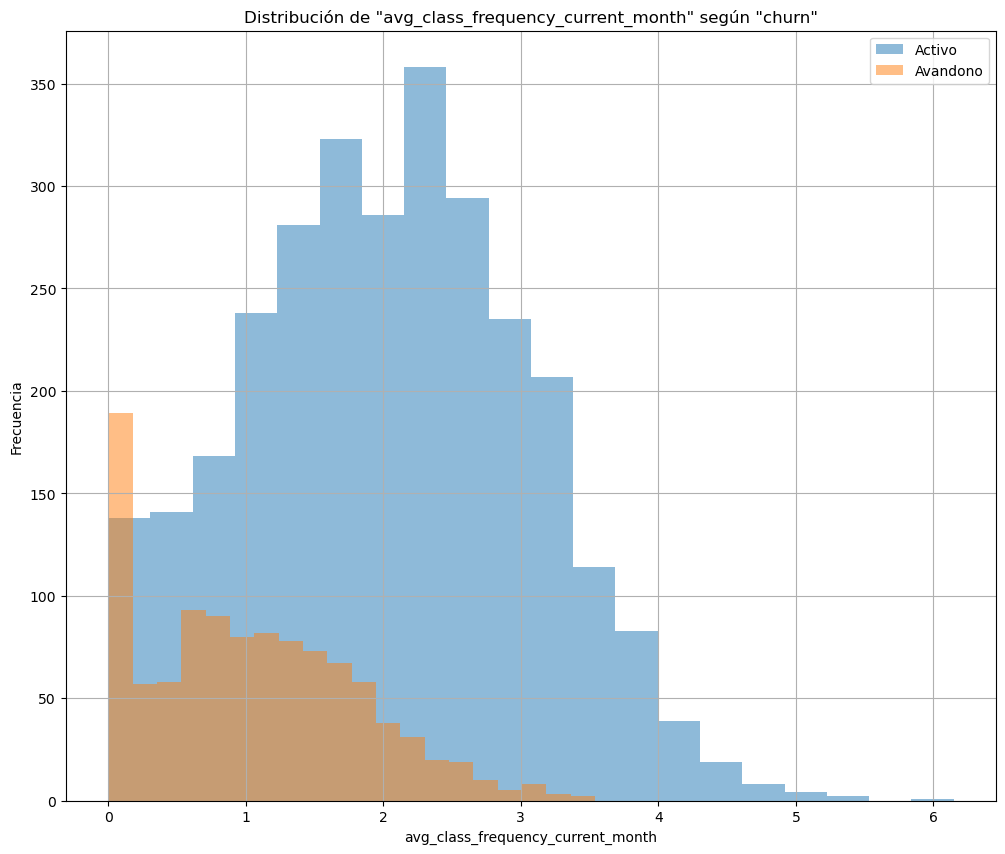

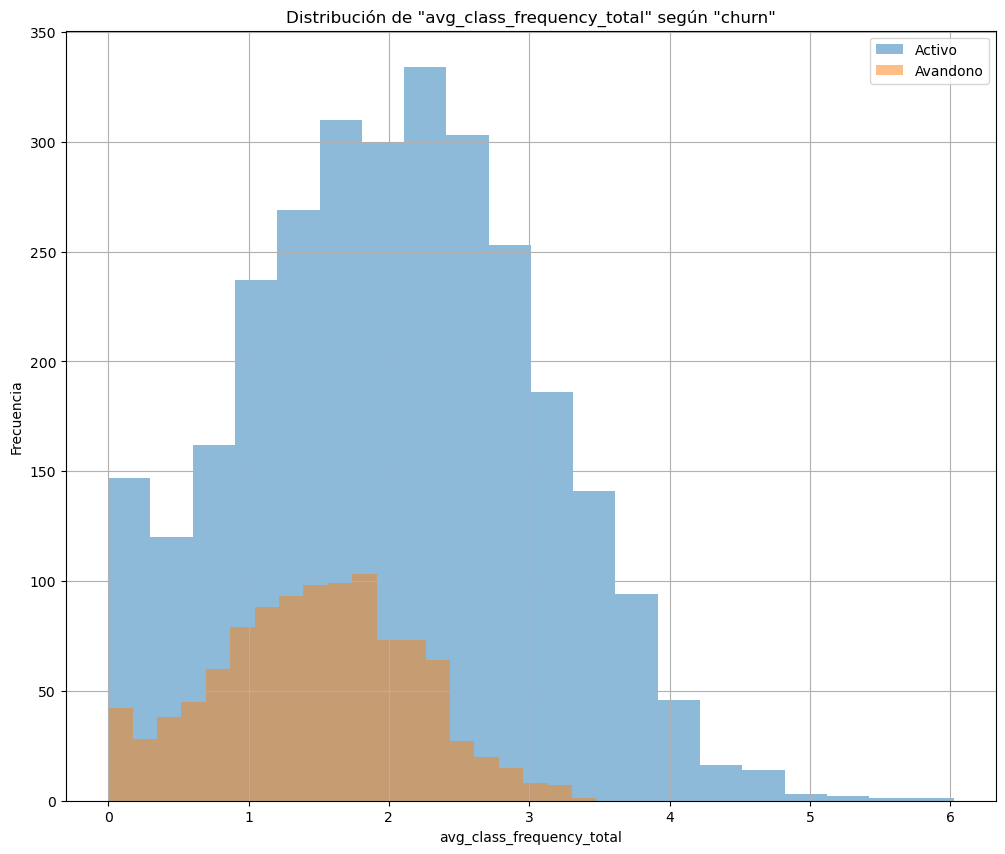

In [53]:
numerical_variables = ['age', 'avg_additional_charges_total', 'month_to_end_contract', 'lifetime', 'avg_class_frequency_current_month',  'avg_class_frequency_total']

for variable in numerical_variables:
    plt.figure(figsize=(12, 10))
    df[df['churn'] == 0][variable].hist(bins=20, alpha=0.5, label='Activo')
    df[df['churn'] == 1][variable].hist(bins=20, alpha=0.5, label='Avandono')
    plt.xlabel(f'{variable}')
    plt.ylabel('Frecuencia')
    plt.title(f'Distribución de "{variable}" según "churn"')
    plt.legend()
    plt.show()

En la primra grafica (edad Vs Avandono), se puede observar que las personas  que abandonan son jovenes entre 25 y 30 años, las personas que permanecen se concentra en las edasdes de 30 y 32 años

En la segunda grafica (gastos adicionales vs churn) presenta una cola más larga hacia la derecha, lo que indica que los usuarios que consumen los servicios extra tienen un mayor nivel de compromiso con el gimnasio, al contario de los que abandonan pues tenen muy poco consumo.

Para la tercera grafica (antiguedad vs churn) muestra un pico en el primer mes, pero si un cliente supera los primeros 2 o 3 meses la probabilidad de que cancele va disminuyendo

Para la cuarta grafica (Asistencia en el mes actual vs churn) se observa que el abandono se acumula fuertemente hacia la izquierda, con un pico en la 1ra visita semanal, las personas activas tienen una distribución acampanada (normal) centrada alrededor de 2 a 3 visitas por semana

Para la ultima grafica (Historial de asistencia vs churn) Muestra un comportamiento similar al mes actual (de campana) para las personas que siguen activas

### Mapa de correalacion

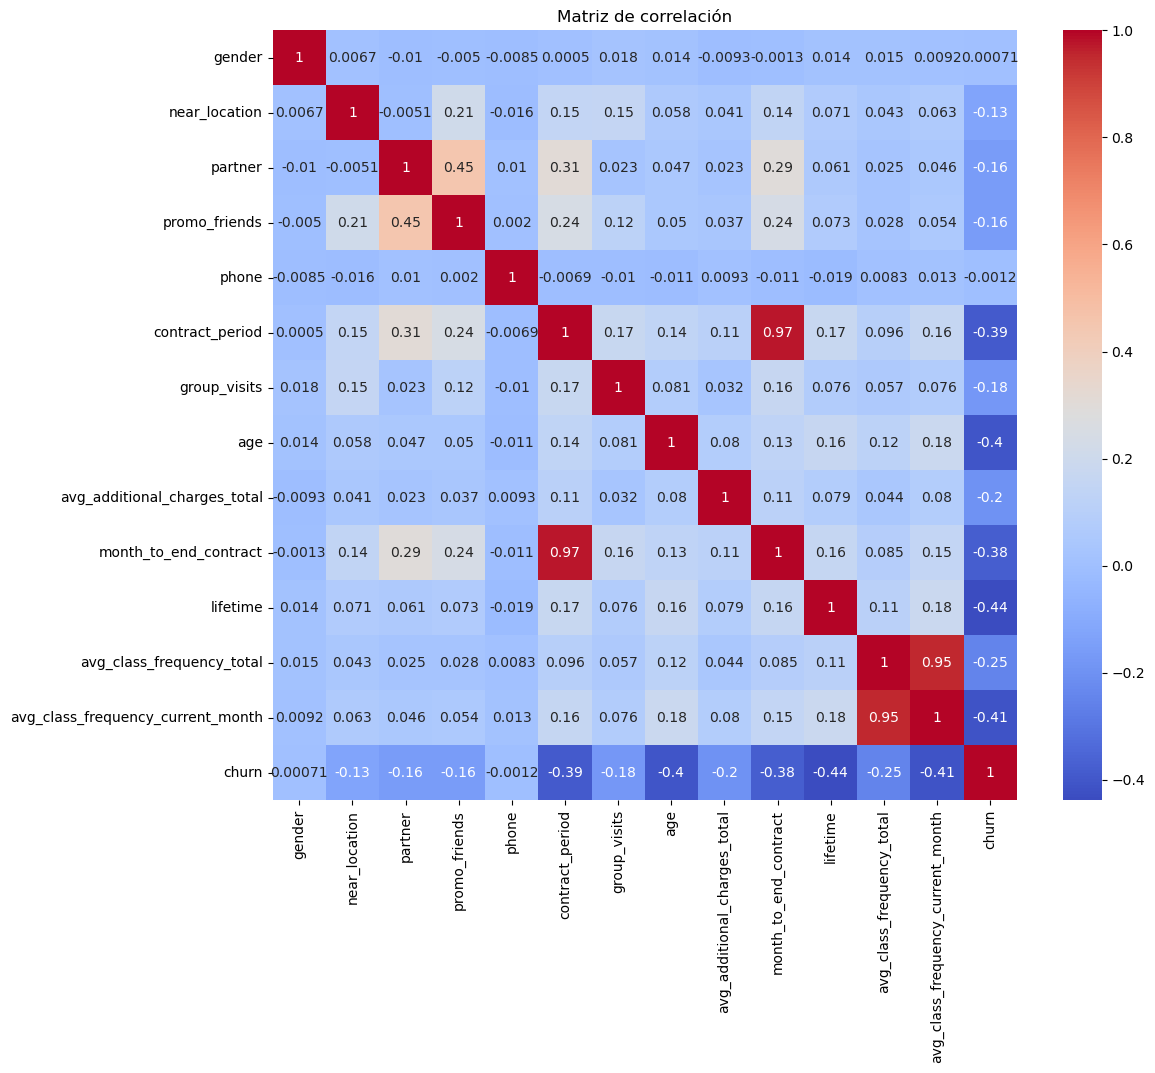

In [54]:
corr_m = df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_m, annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

Cada celda de esta matriz muestra un número entre -1 y 1 que indica qué tan relacionadas están dos variables:

si esta cerca de 1: cuando una sube, la otra también sube (correlación positiva fuerte).
si esta cerca de -1: cuando una sube, la otra baja (correlación negativa fuerte).
si esta cerca de 0: no hay relación lineal clara entre ellas.

se observa que la relacion de Contract_period vs. Month_to_end_contract son las que cumplen con una correlacion positiva fuerte (0.97) y la pareja Avg_class_frequency_total vs. Avg_class_frequency_current_month tambien cumplen con una correlacion positiva fuerte (0.95)

la correlación con la variable objetivo (churn) cuenta varios valores negativos (-0.40 o -0.50) que serian los principales factores contra la cancelación o permanencia

por ultim contract_period VS gender es la que no tiene niguna relacion entre ellas pues su valor es casi nulo (-0.0005)

## Paso 2. Modelo para predecir la cancelación de usuarios

In [55]:
X = df.drop(columns = ['churn'], axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

sc = StandardScaler()
sc.fit(X_train)

# transforma conjuntos de entrenamiento y de prueba
X_train_st = sc.transform(X_train)
X_test_st = sc.transform(X_test)

model_lr = LogisticRegression(random_state=0)
model_lr.fit(X_train_st, y_train)

model_rf = RandomForestClassifier(random_state=0)
model_rf.fit(X_train_st, y_train)

pred_lr = model_lr.predict(X_test_st)
pred_rf = model_rf.predict(X_test_st)

print('Métricas con regresión logística')
print('Accuracy: {:.3f}'.format(accuracy_score(y_test, pred_lr)))
print('Precision: {:.3f}'.format(precision_score(y_test, pred_lr)))
print('Recall: {:.3f}'.format(recall_score(y_test, pred_lr)))
print()
print('Metricas con bosque aleatorio')
print('Accuracy: {:.3f}'.format(accuracy_score(y_test, pred_rf)))
print('Precision: {:.3f}'.format(precision_score(y_test, pred_rf)))
print('Recall: {:.3f}'.format(recall_score(y_test, pred_rf)))

Métricas con regresión logística
Accuracy: 0.922
Precision: 0.854
Recall: 0.828

Metricas con bosque aleatorio
Accuracy: 0.915
Precision: 0.839
Recall: 0.813


El modelo de Bosque Aleatorio ofreció el mejor desempeño global al evaluar los datos sin estandarizar, superando a la Regresión Logística en las tres métricas

El Recall (0.818) de Bosque Aleatorio identifica al 81.8% de los clientes en riesgo de cancelación frente al 80.3% de Regresión Logística, esto permite rescatar a un mayor número de usuarios antes de que abandonen

El 83.9% de los clientes etiquetados como "en riesgo" realmente van a cancelar

## Paso 3. Crear clusteres de usuarios

### Trazar un dendrograma

In [56]:
X = df.drop(columns = ['churn'], axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

sc = StandardScaler()
X_sc = sc.fit_transform(X)

linked = linkage(X_sc, method='ward')
'''
plt.figure(figsize=(15, 10))
dendrogram(linked)
plt.xlabel('Usuarios')
plt.ylabel('Distancia (Ward)')
plt.title('Dendrograma de aglomeraciónjerarquica para el GYM')
plt.show()'''

"\nplt.figure(figsize=(15, 10))\ndendrogram(linked)\nplt.xlabel('Usuarios')\nplt.ylabel('Distancia (Ward)')\nplt.title('Dendrograma de aglomeraciónjerarquica para el GYM')\nplt.show()"

### Modelo de clustering con el algortimo K-means

In [57]:
km = KMeans(n_clusters=5, random_state=0)
labels = km.fit_predict(X_sc)
df['cluster_km'] = labels
avg = df.groupby('cluster_km').mean()

print(avg)

              gender  near_location   partner  promo_friends     phone  \
cluster_km                                                               
0           0.486819       1.000000  0.243409       0.007030  0.899824   
1           0.592493       0.970509  0.288204       0.123324  0.898123   
2           0.499469       0.943677  0.740701       0.489904  0.900106   
3           0.483360       1.000000  0.798732       1.000000  0.911252   
4           0.496324       0.000000  0.466912       0.077206  0.915441   

            contract_period  group_visits        age  \
cluster_km                                             
0                  1.978910      0.326889  28.239016   
1                  2.898123      0.482574  30.339142   
2                 11.866100      0.551541  29.905420   
3                  3.079239      0.445325  29.052298   
4                  2.209559      0.215074  28.483456   

            avg_additional_charges_total  month_to_end_contract  lifetime  \
cluster_km 

Al anamizar las medias de los clusters, el cluster 2 presenta el menor nivel de abandono (0.022) en 'churn' pero en otras columnas como 'month_to_end_contract',  'contract_period', 'group_visits' el promedio de ese cluster es mayor en comparacion de los otros de la columna teniendo un mayor compromiso por parte de los clientes ; el cluster 0 presenta el menor nivel de abandono donde tiene promedio mas alto (0.513) en 'churn' pero en otras columnas como 'month_to_end_contract', 'life_time', 'contract_period', 'group_visits' y 'promo friens' el promedio de ese cluster es menor en comparacion de los otros de la columna teniendo un menor compromiso por parte de los clientes

### Distribuciones de los clústeres

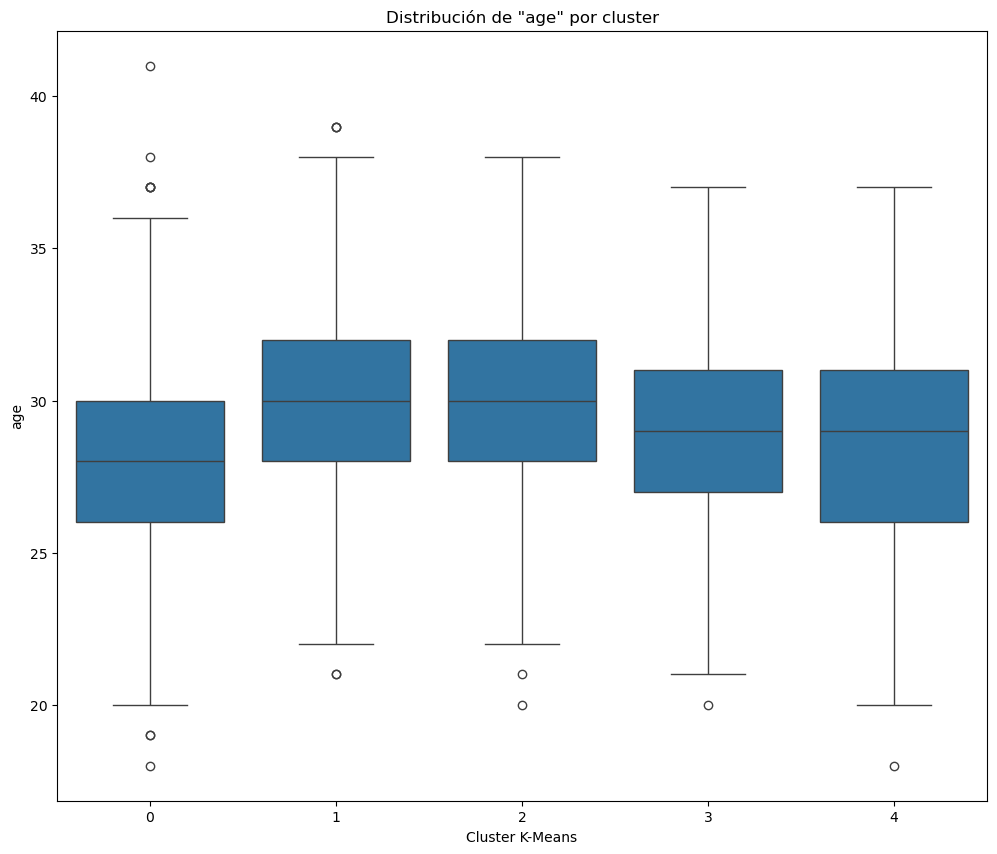

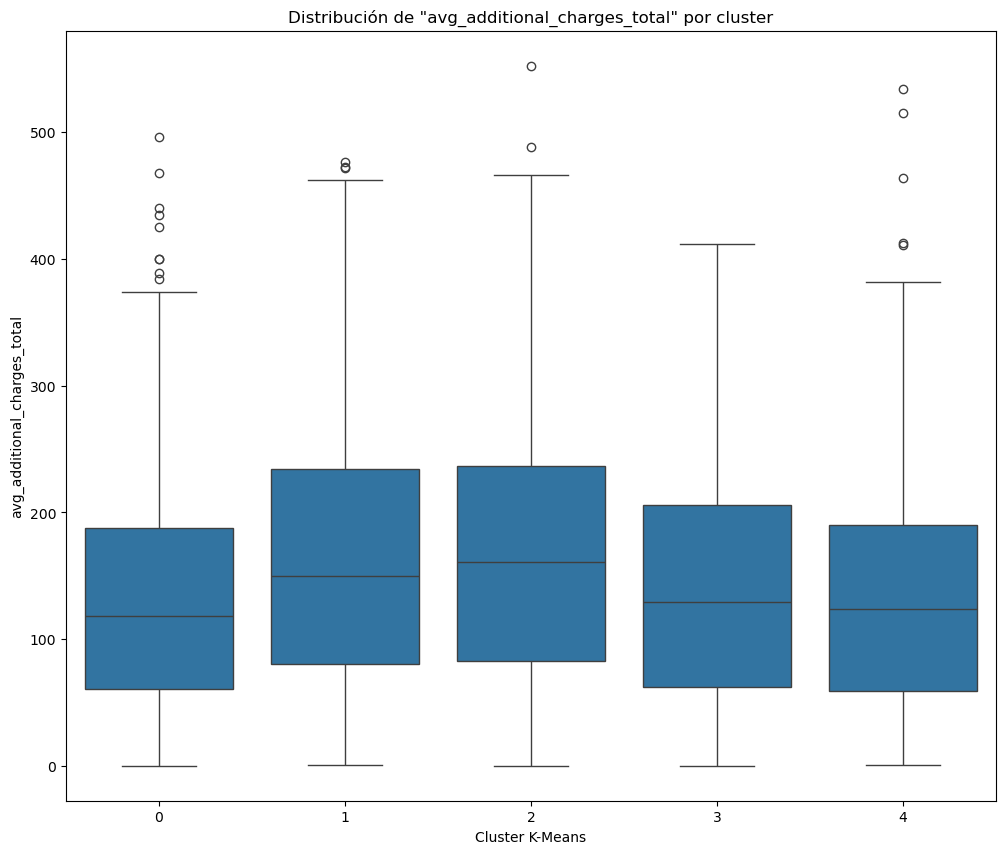

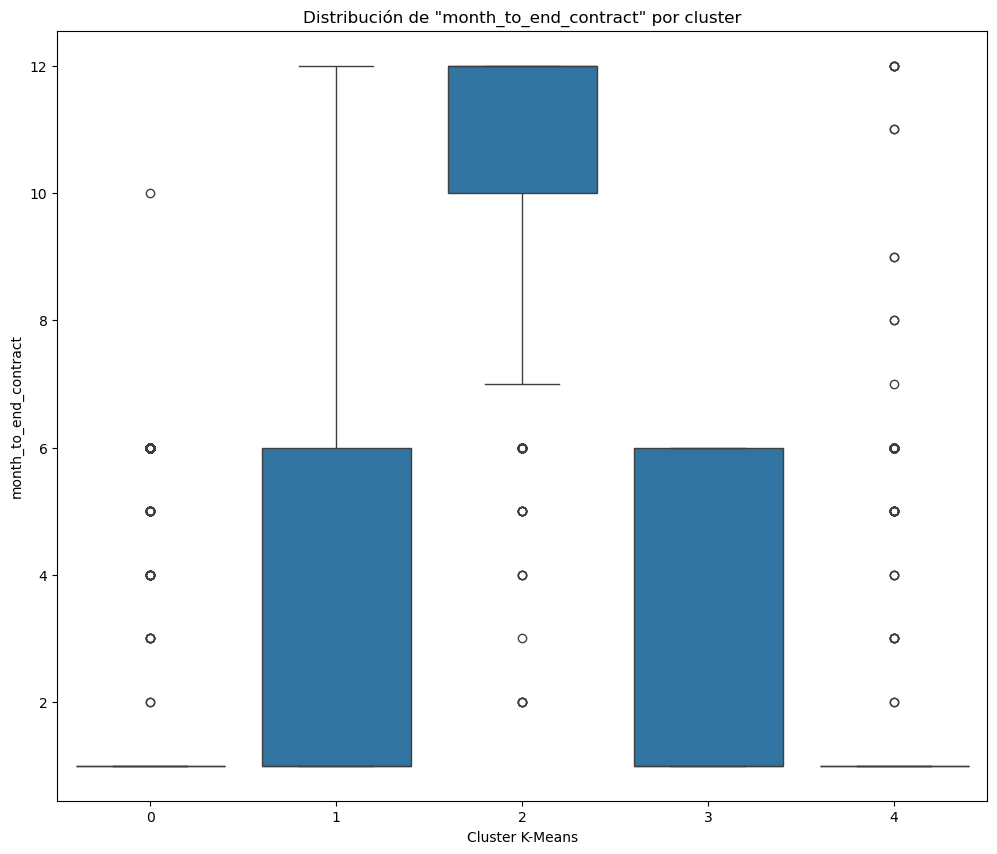

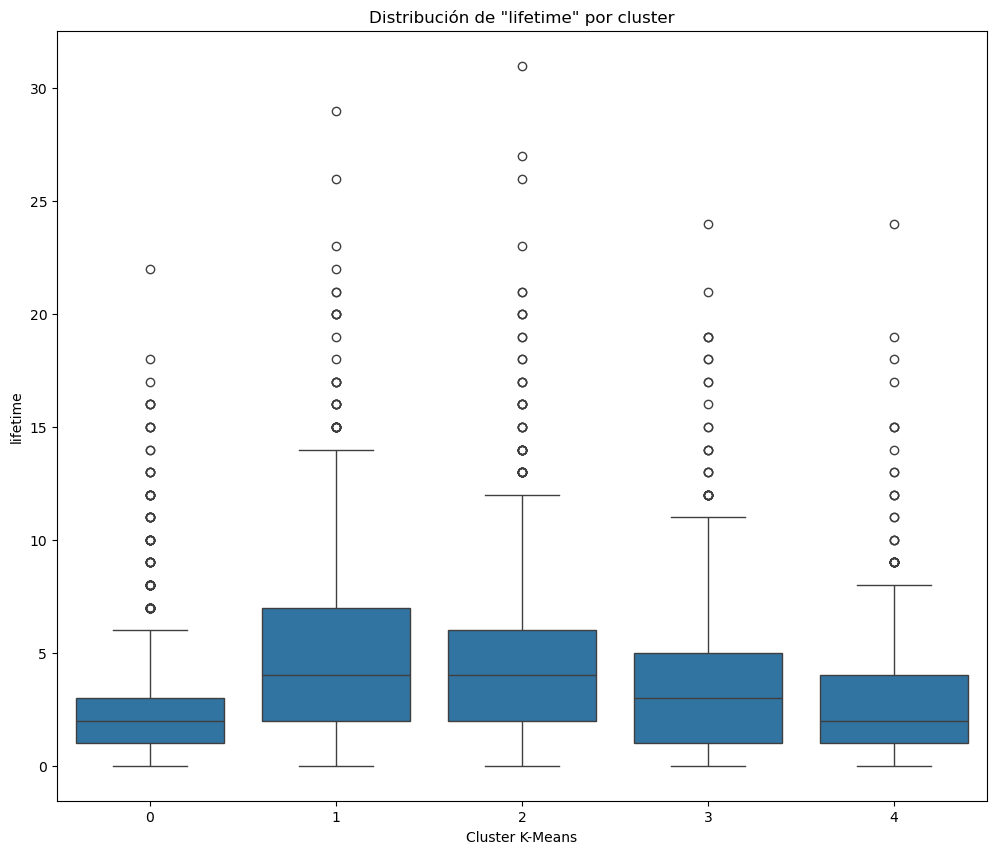

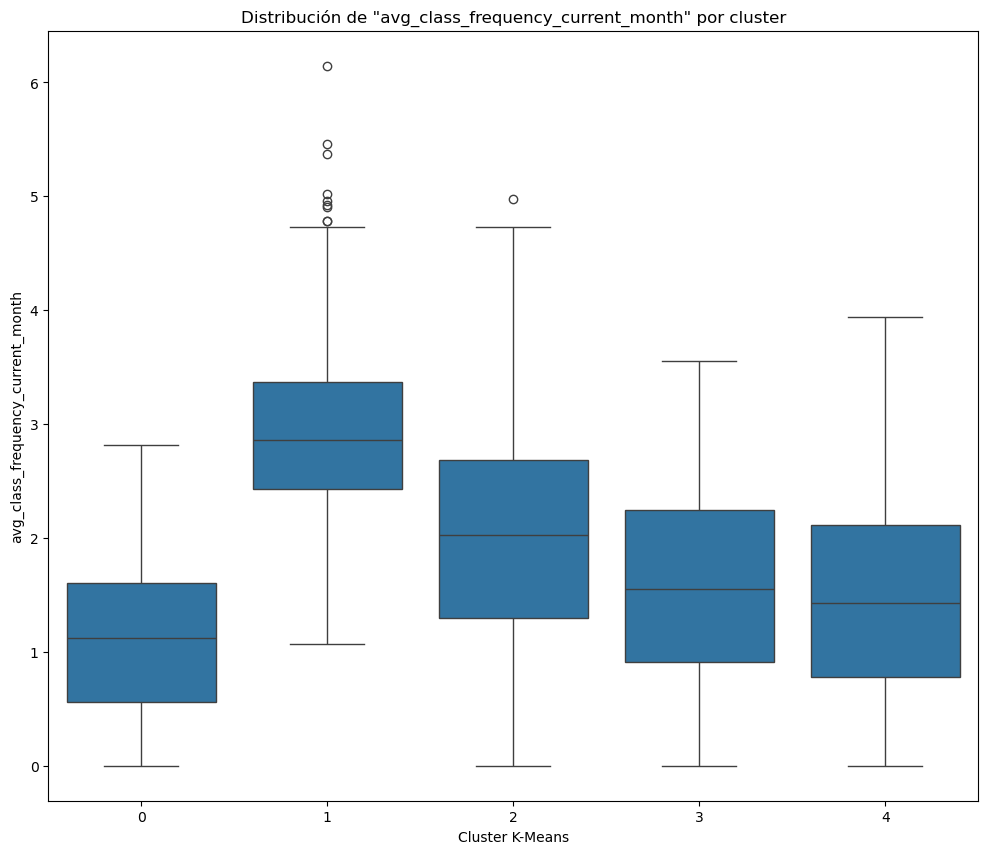

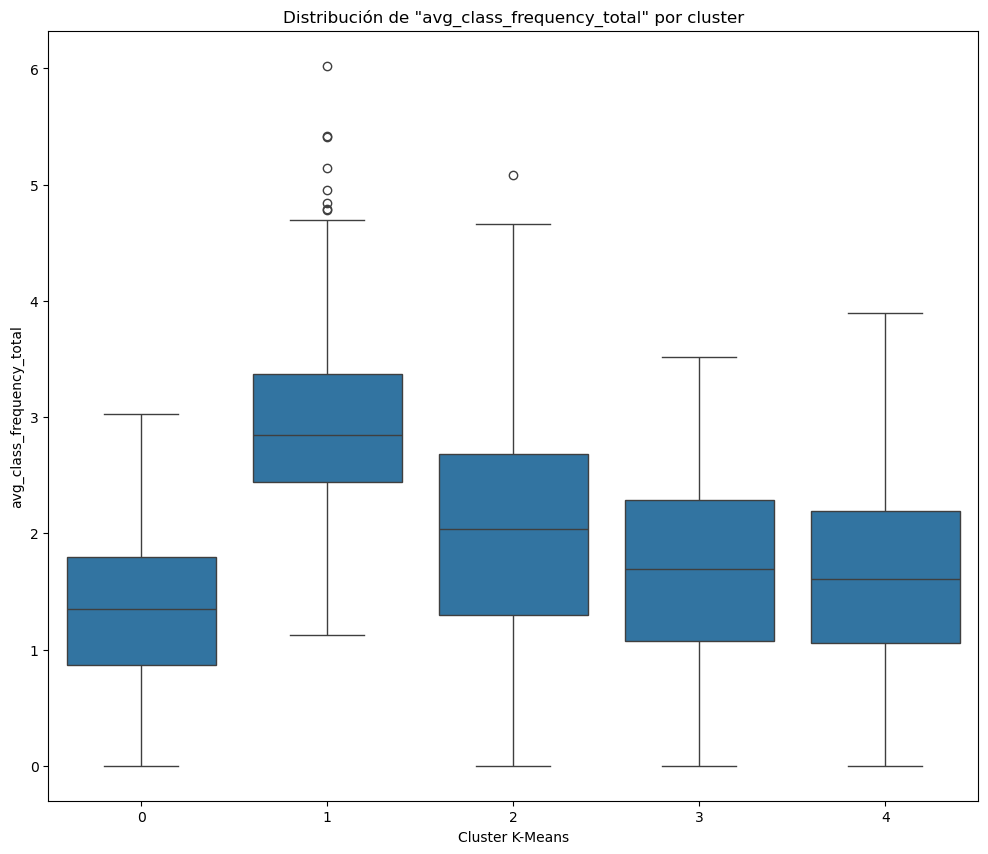

In [58]:
numerical_variables = ['age', 'avg_additional_charges_total', 'month_to_end_contract', 'lifetime', 'avg_class_frequency_current_month',  'avg_class_frequency_total']

for variable in numerical_variables:
    plt.figure(figsize=(12, 10))
    sns.boxplot(x='cluster_km', y=variable, data=df)
    plt.xlabel('Cluster K-Means')
    plt.ylabel(f'{variable}')
    plt.title(f'Distribución de "{variable}" por cluster')
    plt.show()

En el diagrama 'month_to_end_contract', el cluster 2 oncentra a usuarios con contratos a largo plazo (entre 10 y 12 meses), es el gurpo mas leal
El cluster 0 y 4 se colapsan en el pirmer mes, lo que indica que tienen contrataciones a muy corto plazo, lo que incrementa fuertemente su riesgo de abandono al finalizar el mes.
Y los cluster 1 y 3 son los mas estables

para los dos diagramas de 'avg_class_frequency_current_month' y 'avg_class_frequency_total' se comportan de manera similar ya que en el clúster 1 tiene un segmento de alta intensidad de entrenamiento, con medidas de 3 visitas por semana, el cluster 2 se mantiene constante (alrededor de 2 visitas semanales), el cluster 0 muestra una caída en la asistencia del mes actual (cerca a 1 visita por semana) demostrando un desinterés previo a la baja

en el diagrama 'lifetime' el cluster 0 y 4 registran la antigüedad más baja (2 meses) demostrando que la mayor parte del abandono ocurre en la etapa de iniciacion   

en el diagrama 'avg_additional_charges_total' los clusteres 1 y 2 muestran cajas inclinadas a los gasto más altos lo que refleja una mayor vinculación con los servicios adicionales del gimnasio y los clusters 0 y 4 gastan significativamente menos

el diagrama 'age' los clusters 1 y 2 agrupan a los usuarios con una mediana de edad alrededor de 30 años y el cluster 0 concentra al grupo de usuarios de 28 años

### Tasa de cancelación para cada clúster

In [59]:
avg = df.groupby('cluster_km')['churn'].mean()
print(avg)

cluster_km
0    0.513181
1    0.054960
2    0.022317
3    0.269414
4    0.450368
Name: churn, dtype: float64


los usuarios del clusters 1 y 2 se consideran los usurios "leales" ya que cuentan con contratos largos de 6 a 12 meses, con alta asistencia semanal (2 a 3 clases), mayor edad promedio (alrededor de 30 años) y alto consumo en servicios adicionales

los usurios del cluster 0 se consideran los usuarios con mayor riesgo de abandono ya que son usurios que tienen contratos mensuales de 1 mes, baja antigüedad y una inasistencia mayor durante el último mes

Para los usurios del cluster 3 son un grupo estable/regular pero que requiere monitoreo ocasional para evitar el abandono

Los clusters sson diferentes en sus tasas de cancelación, esto demuestra que la estrategia de retención no debe aplicarse a toda la base, sino concentrarse principalmente en los usuarios del cluster 0 desde sus primeras dos semanas de ingreso

In [60]:
# cuantos usuarios hay en cada cluster
conteo_clusters = df['cluster_km'].value_counts().sort_index()

# Calcular el porcentaje que representa cada cluster (frecuencia relativa)
porcentaje_clusters = df['cluster_km'].value_counts(normalize=True).sort_index() * 100

# Unir ambos resultados en un DataFrame limpio para presentarlo
balance_clusters = pd.DataFrame({
    'cantidad usuarios': conteo_clusters,
    'porcentaje': porcentaje_clusters
})

print("Balanceo de los Clusters")
print(balance_clusters.round(2))

Balanceo de los Clusters
            cantidad usuarios  porcentaje
cluster_km                               
0                        1138       28.45
1                         746       18.65
2                         941       23.52
3                         631       15.78
4                         544       13.60


El mayor riesgo está concentrado en el grupo más grande cluster 3 (31.55%) tiene una tasa de abandono muy grande, essto significa que casi un tercio de los clientes totales de la plataforma sson mas propensos a irse y los segmentos del Clusters 0 y 4 (los usuarios leales) suman en conjunto cerca del 46.2% de la base de usuarios y presentan tasas de churn muy bajas

## Paso 5. Conclusiones y recomendaciones

  1. Conclusiones Generales del Proyecto

**Identificación de usuarios en riesgo:** El factor para prevenir la cancelación de un cliente se concentra en los primeros 2 meses (`lifetime`) y en su rutina de asistencia del mes en curso (`avg_class_frequency_current_month`)

**Modelo Predictivo:** El algoritmo de Bosque Aleatorio (Random Forest) demostró un Recall del 81.8% y una Precision del 83.9%, lo que permitio identificar con los clientes en riesgo antes de que se marchen


**Segmentación (Clustering):**

**Grupo Leal (Clúster 2 y 1):** So los clientes que tienen contratos de 6 a 12 meses, participan en clases grupales, asisten 2-3 veces por semana y realizan un mayor gasto en servicios adicionales.

**Grupo que abandona (Clúster 0):** Registra una tasa de abandono superior al 50%, caracterizándose por contratos de 1 mes, baja asistencia y poca participación en los servicios adicionales del gimnasio.

  
  2. Principios Esenciales

 **Principio 1: Fortalecer la Etapa de Iniciacion**

 **Objetivo:** Superar la barrera crítica de los primeros 60 días en los usuarios de nuevo ingreso (Clúster 0)

 **Paso de Marketing:** Diseñar un "Paquete/Plan de Bienvenida de 30 Días" que incluya una evaluación física gratuita o dos sesiones personalizadas con un entrenador personalizado al momento de inscribirse para asegurar que el cliente cree un hábito de entrenamiento desde las primeras semanas

 **Principio 2: Promover Contratos de Larga Duración e Incentivos de Membresía**

 **Objetivo:** Proporcionar a los usuarios de contratos de 1 mes hacia planes de 6 o 12 meses

 **Paso de Marketing:** Ofrecer descuentos o meses adicionales de regalo si el usuario renueva a un plan semestral/anual antes de finalizar su primer mes

 **Principio 3: Detección Automática en Usurios de abandono**

 **Objetivo:** Actuar antes de que el cliente tome la decisión de cancelar

 **Paso de Marketing:** Configurar alertas automáticas en el sistema para que cuando un usuario disminuya su asistencia semanal en un periodo de 14 días, reciba un mensaje de texto ofreciéndole una clase grupal gratuita o una sesión de reactivación